In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [1]:
from calibrate import calibrate
# Calibrate camera and save to a pickle file.
calibrate("./calib/*.png", "calibration.pickle")

Estimated camera intrinsic parameter matrix K
[[1.41154882e+03 0.00000000e+00 9.70034209e+02]
 [0.00000000e+00 1.40635597e+03 5.88794493e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Estimated radial distortion coefficients
[[ 0.00857498 -0.06502574 -0.00113283  0.00050176  0.10241516]]
Individual intrinsic parameters
fx =  1411.5488191840743
fy =  1406.355970927954
cx =  970.0342085196356
cy =  588.7944925188456
Estimated extrinsic parameters (rotation vectors and translation vectors)
Image 1:
Rotation vector:
 [[0.23410334]
 [0.70084019]
 [0.04594755]]
Translation vector:
 [[-11.55933927]
 [-11.00963645]
 [ 60.68043487]]
Image 2:
Rotation vector:
 [[0.23770832]
 [0.91162169]
 [0.07388479]]
Translation vector:
 [[ -8.66043675]
 [-10.66817015]
 [ 58.59316707]]
Image 3:
Rotation vector:
 [[ 0.22275212]
 [ 0.18904009]
 [-0.01547136]]
Translation vector:
 [[-11.31027179]
 [ -7.58827963]
 [ 46.66384569]]
Image 4:
Rotation vector:
 [[ 0.20343096]
 [-0.4935585 ]
 [-0.10026307]]
Trans

### Decoding gray code

In [11]:
# converts a gray code to binary
def gray_to_binary(gray: int) -> int:
   binary = gray
   mask = gray
   while mask != 0:
      mask >>= 1
      binary ^= mask
   return binary

def decode(folder, camera, start, threshold):
   """
   Given a sequence of 20 images of a scene showing projected 10 bit gray code, 
   decode the binary sequence into a decimal value in (0,1023) for each pixel.
   Mark those pixels whose code is likely to be incorrect based on the user 
   provided threshold.  Images are assumed to be named "imageprefixN.png" where
   N is a 2 digit index (e.g., "img00.png,img01.png,img02.png...")

   Parameters
   ----------
   folder : str
      Folder where the images are stored

   camera : str
      Either C0 or C1 depending on the camera used
   
   start : int
      Starting index
      
   threshold : float
      Threshold to determine if a bit is decodeable
      
   Returns
   -------
   code : 2D numpy.array (dtype=float)
      Array the same size as input images with entries in (0..1023)
      
   mask : 2D numpy.array (dtype=logical)
      Array indicating which pixels were correctly decoded based on the threshold
   
   """
   
   # we will assume a 10 bit code
   nbits = 10
   
   # don't forget to convert images to grayscale / float after loading them in
   images = []
   for i in range(20):
      img = plt.imread(f"{folder}/frame_{camera}_{start+i:02d}_u.png")
      if img.ndim == 3:
         img = np.mean(img,axis=2)
      images.append(img)

   threshold_mask = np.ones_like(images[0],dtype=bool)
   code = np.zeros_like(images[0],dtype=float)

   # 10 binary images
   binary_images = np.zeros((nbits,images[0].shape[0],images[0].shape[1]),dtype=float)
   for i in range(nbits):
      # get the ith image
      binary_images[i] = images[i*2] - images[i*2+1]
      # update the mask
      threshold_mask[np.abs(binary_images[i]) < threshold] = False
      # threshold it
      binary_images[i][binary_images[i] < 0] = 0
      binary_images[i][binary_images[i] > 0] = 1
      
   # now we have 10 binary images, we need to convert them to a decimal value
   for i in range(nbits):
      code += binary_images[i] * (2**(nbits-i-1))
   code = np.vectorize(gray_to_binary)(code.astype(int))
        
   return code, threshold_mask

In [21]:
def compute_object_mask(folder, camera, threshold):
   """
   Compute the object mask from the decoded images.
   
   Parameters
   ----------
   folder : str
      Folder where the images are stored

   camera : str
      Either C0 or C1 depending on the camera used
   
   threshold : float
      Threshold to determine if a pixel is part of the object mask
      
   Returns
   -------
   mask : 2D numpy.array (dtype=logical)
      Array indicating which pixels are part of the object mask
   """
   
   bg_img = plt.imread(f"{folder}/color_{camera}_00_u.png")
   obj_img = plt.imread(f"{folder}/color_{camera}_01_u.png")
   subtracted = bg_img - obj_img
   obj_mask = np.ones_like(subtracted, dtype=bool)
   obj_mask[np.abs(subtracted) < threshold] = False
   obj_mask = np.any(obj_mask, axis=2)  # Convert to a 2D mask by checking all color channels

   return obj_mask

In [34]:
def get_masked_code(folder, code_threshold, object_threshold, display=False):
    """
    Get the masked code and object mask for both cameras.
    
    Parameters
    ----------
    folder : str
        Folder where the images are stored
    
    code_threshold : float
        Threshold to determine if a pixel is decodeable
        
    object_threshold : float
        Threshold to determine if a pixel is part of the object mask
        
    display : bool
        If True, display the results
    
    Returns
    -------
    H1, Hmask1, V1, Vmask1, obj_mask1 : 2D numpy.array
        Horizontal code, horizontal mask, vertical code, vertical mask, and object mask for camera C0
    
    H2, Hmask2, V2, Vmask2, obj_mask2 : 2D numpy.array
        Horizontal code, horizontal mask, vertical code, vertical mask, and object mask for camera C1
    """
    
    
    #
    # Visualize results for the first scan and experiment to determine a good threshold
    #
    H1,Hmask0 = decode(folder, 'C0', 0, code_threshold)
    V1,Vmask0 = decode(folder, 'C0', 20, code_threshold)
    H2,Hmask1 = decode(folder, 'C1', 0, code_threshold)
    V2,Vmask1 = decode(folder, 'C1', 20, code_threshold)

    obj_mask0 = compute_object_mask(folder, 'C0', object_threshold)
    obj_mask1 = compute_object_mask(folder, 'C1', object_threshold)

    M0 = Hmask0 & Vmask0 & obj_mask0
    M1 = Hmask1 & Vmask1 & obj_mask1
    C0 = 1024 * H1 + V1
    C1 = 1024 * H2 + V2
    C0[M0==False] = 0
    C1[M1==False] = 0

    if display:
        # display visualizaitons of the first scan
        fig,ax = plt.subplots(7,2, figsize=(8,14))
        fig.suptitle('First Scan', fontsize=16)
        ax[0,0].imshow(H1)
        ax[0,0].set_title('Horizontal Code (C0)')
        ax[0,1].imshow(H2)
        ax[0,1].set_title('Horizontal Code (C1)')
        ax[1,0].imshow(Hmask0)
        ax[1,0].set_title('Horizontal Mask (C0)')
        ax[1,1].imshow(Hmask1)
        ax[1,1].set_title('Horizontal Mask (C1)')
        ax[2,0].imshow(V1)
        ax[2,0].set_title('Vertical Code (C0)')
        ax[2,1].imshow(V2)
        ax[2,1].set_title('Vertical Code (C1)')
        ax[3,0].imshow(Vmask0)
        ax[3,0].set_title('Vertical Mask (C0)')
        ax[3,1].imshow(Vmask1)
        ax[3,1].set_title('Vertical Mask (C1)')
        ax[4,0].imshow(obj_mask0)
        ax[4,0].set_title('Object Mask (C0)')
        ax[4,1].imshow(obj_mask1)
        ax[4,1].set_title('Object Mask (C1)')
        ax[5,0].imshow(M0)
        ax[5,0].set_title('Combined Mask (C0)')
        ax[5,1].imshow(M1)
        ax[5,1].set_title('Combined Mask (C1)')
        ax[6,0].imshow(C0)
        ax[6,0].set_title('Combined Code (C0)')
        ax[6,1].imshow(C1)
        ax[6,1].set_title('Combined Code (C1)')
        for axis in ax.flat:
            axis.axis('off')
        plt.show()

    return C0, C1

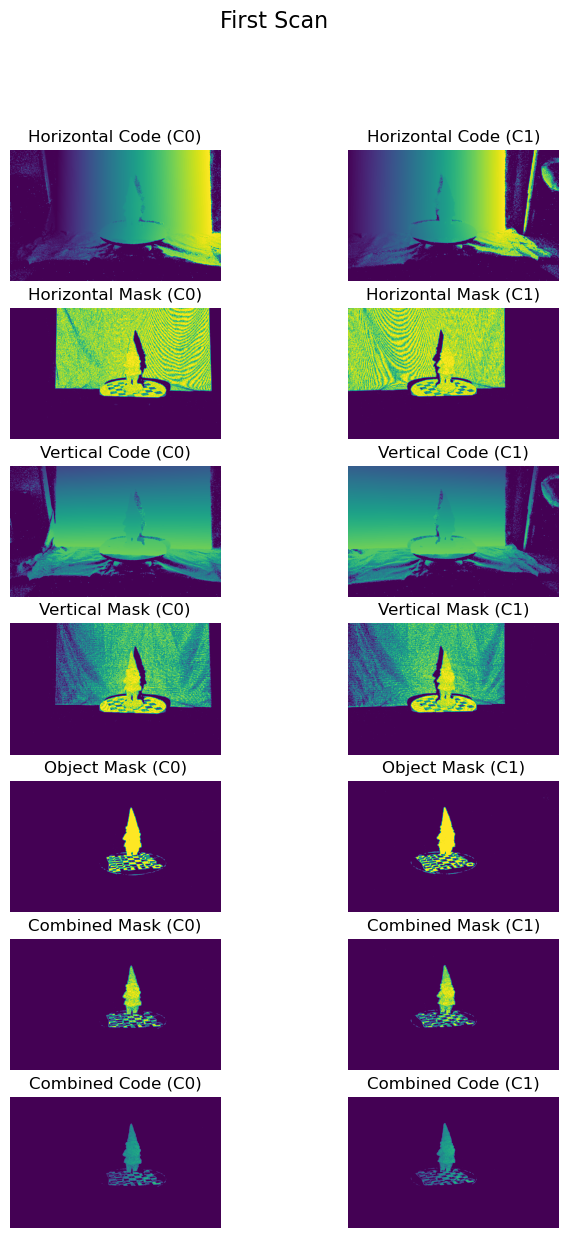

In [41]:
C0, C1 = get_masked_code("./david/grab_0", 0.005, 0.15, display=True)